In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [2]:
df = pd.read_csv("../Data/Cleaned/Plant_2_Feature_Engineered.csv")

df.head()


,PLANT_ID,SOURCE_KEY_x,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_y,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,DAY,MONTH,WEEKDAY,IS_WEEKEND
0,4136001,0,0.0,0.0,9425.000000,2.429011e+06,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,0,15,5,4,0
1,4136001,1,0.0,0.0,0.000000,1.215279e+09,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,0,15,5,4,0
2,4136001,2,0.0,0.0,3075.333333,2.247720e+09,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,0,15,5,4,0
3,4136001,3,0.0,0.0,269.933333,1.704250e+06,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,0,15,5,4,0
4,4136001,4,0.0,0.0,3177.000000,1.994153e+07,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,0,15,5,4,0


In [3]:
X = df.drop(columns=["AC_POWER","SOURCE_KEY_y","DC_POWER","DAILY_YIELD","TOTAL_YIELD","PLANT_ID"])

y = df["AC_POWER"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=14
)


In [4]:
lr = LinearRegression()

lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
r2_lr = r2_score(y_test, pred_lr)

print("MAE :", mae_lr)

print("RMSE :", rmse_lr)

print("R2 :", r2_lr)


MAE : 124.76957926218147
RMSE : 222.95045635573888
R2 : 0.617175887744329


In [5]:
dt = DecisionTreeRegressor(random_state=14)

dt.fit(X_train, y_train)

pred_dt = dt.predict(X_test)

mae_dt = mean_absolute_error(y_test, pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, pred_dt))
r2_dt = r2_score(y_test, pred_dt)

print("MAE :", mae_dt)

print("RMSE :", rmse_dt)

print("R2 :", r2_dt)


MAE : 42.705698011245275
RMSE : 162.7101827391054
R2 : 0.7961024447981038


In [6]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=14
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
r2_rf = r2_score(y_test, pred_rf)

print("MAE :", mae_rf)

print("RMSE :", rmse_rf)

print("R2 :", r2_rf)


MAE : 42.834021702079305
RMSE : 120.95300685144252
R2 : 0.8873280290781163


In [7]:
gb = GradientBoostingRegressor(random_state=14)

gb.fit(X_train, y_train)

pred_gb = gb.predict(X_test)

mae_gb = mean_absolute_error(y_test, pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, pred_gb))
r2_gb = r2_score(y_test, pred_gb)

print("MAE :", mae_gb)

print("RMSE :", rmse_gb)

print("R2 :", r2_gb)


MAE : 87.22310462520784
RMSE : 195.31471776289624
R2 : 0.7061995250083841


In [8]:
xgb = XGBRegressor(
    n_estimators=100,
    random_state=14
)

xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)

mae_xgb = mean_absolute_error(y_test, pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, pred_xgb))
r2_xgb = r2_score(y_test, pred_xgb)

print("MAE :", mae_xgb)

print("RMSE :", rmse_xgb)

print("R2 :", r2_xgb)


MAE : 56.615291139483915
RMSE : 141.55640276293568
R2 : 0.8456731156693759


In [9]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting", "XGBoost"],
    "MAE": [mae_lr, mae_dt, mae_rf, mae_gb, mae_xgb],
    "RMSE": [rmse_lr, rmse_dt, rmse_rf, rmse_gb, rmse_xgb],
    "R2 Score": [r2_lr, r2_dt, r2_rf, r2_gb, r2_xgb]
})

results


,Model,MAE,RMSE,R2 Score
0,Linear Regression,124.769579,222.950456,0.617176
1,Decision Tree,42.705698,162.710183,0.796102
2,Random Forest,42.834022,120.953007,0.887328
3,Gradient Boosting,87.223105,195.314718,0.706200
4,XGBoost,56.615291,141.556403,0.845673


In [10]:
importance_rf = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

importance_xgb = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
}).sort_values(by="Importance", ascending=False)

importance_rf


,Feature,Importance
3,IRRADIATION,0.707426
0,SOURCE_KEY_x,0.111428
5,DAY,0.054106
2,MODULE_TEMPERATURE,0.042685
1,AMBIENT_TEMPERATURE,0.031462
7,WEEKDAY,0.027900
4,HOUR,0.013827
6,MONTH,0.007018
8,IS_WEEKEND,0.004149


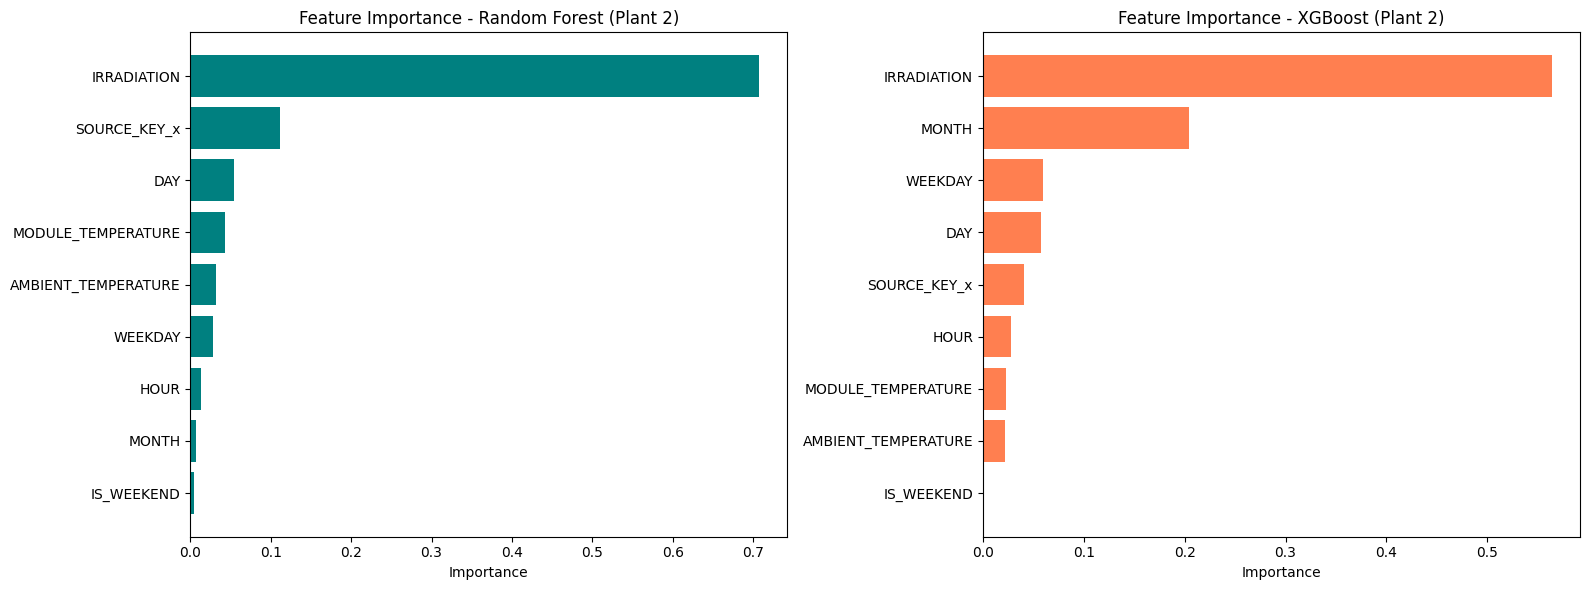

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(importance_rf["Feature"], importance_rf["Importance"], color="teal")
axes[0].set_title("Feature Importance - Random Forest (Plant 2)")
axes[0].set_xlabel("Importance")
axes[0].invert_yaxis()

axes[1].barh(importance_xgb["Feature"], importance_xgb["Importance"], color="coral")
axes[1].set_title("Feature Importance - XGBoost (Plant 2)")
axes[1].set_xlabel("Importance")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


# Machine Learning Model Evaluation & Analysis (Plant 2)

Five regression algorithms were trained and evaluated for **Plant 2**:
1. **Linear Regression**
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **Gradient Boosting Regressor**
5. **XGBoost Regressor**

## Observations

- **Random Forest Regressor achieved the best overall performance** on Plant 2, attaining an $R^2$ score of **0.8873**, with the lowest RMSE of **120.95 kW** and lowest MAE of **42.83 kW**.
- **XGBoost** achieved the second-highest performance with an $R^2$ score of **0.8457** and RMSE of **141.56 kW**.
- **Decision Tree** achieved an $R^2$ of **0.7961**, while **Gradient Boosting** achieved **0.7062**.
- **Linear Regression** struggled significantly on Plant 2, attaining only an $R^2$ of **0.6172** and RMSE of **222.95 kW**, highlighting the highly non-linear nature of Plant 2 generation.

## Feature Importance Comparison

- In Plant 2, while solar irradiation remains the leading predictor (~70.7% in RF, ~56.4% in XGBoost), inverter identity (`SOURCE_KEY_x`) and calendar variables (`DAY`, `MONTH`, `WEEKDAY`) carry substantially higher weight than in Plant 1.
- Inverter heterogeneity indicates significant differences in operating output and string efficiency among the 22 inverters at Plant 2.

## Conclusion

Tree-based ensemble models substantially outperform linear models on Plant 2. **Random Forest Regressor** delivers the highest accuracy and stability on Plant 2, with **XGBoost** serving as a competitive second alternative.
